<a href="https://colab.research.google.com/github/Lukecele/spatial-game-assay/blob/main/notebooks/InSituGame_PanCancer_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# InSituGame: In Situ Spatial Evolutionary Game Assay
### Quantifying Tumor Clonal Ecology and Game Dynamics Directly from Intact Human Tissue

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Lukecele/spatial-game-assay/blob/main/notebooks/InSituGame_PanCancer_Colab.ipynb)

**Author:** Luca Celebrano (School of Medicine and Surgery, Università degli Studi di Napoli Federico II)  
**Repository:** [https://github.com/Lukecele/spatial-game-assay](https://github.com/Lukecele/spatial-game-assay)  

---

This interactive notebook executes the complete **InSituGame** pipeline on Google Cloud (Colab):
1. **Spatial Delaunay Network Extraction** on 10x Visium clinical transcriptomics
2. **Microenvironmental Decoupling** via the Frisch-Waugh-Lovell projection
3. **Absorbed Payoff Matrix Estimation** ($\\tilde{A}$) on the 2-simplex
4. **Replicator Dynamics & Adaptive Therapy** phase-space simulation
5. **Spatial Autocorrelation (Moran's I) & Null Permutations**

In [11]:
# Step 1: Clone Repository and Setup Dependencies
import os
if os.path.exists("/content"):
    os.chdir("/content")
    if not os.path.exists("/content/spatial-game-assay"):
        !git clone https://github.com/Lukecele/spatial-game-assay.git
    os.chdir("/content/spatial-game-assay")
    !git pull origin main

!pip install -q numpy scipy pandas scikit-learn matplotlib


remote: Enumerating objects: 8, done.
remote: Counting objects: 100% (8/8), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 8 (delta 2), reused 8 (delta 2), pack-reused 0 (from 0)
Unpacking objects: 100% (8/8), 72.94 KiB | 1.14 MiB/s, done.
From https://github.com/Lukecele/spatial-game-assay
 * branch            main       -> FETCH_HEAD
   af428fd..3229081  main       -> origin/main
Updating af428fd..3229081
Fast-forward
 README.md                                  |   2 +-
 notebooks/InSituGame_PanCancer_Colab.ipynb | 451 +++++++----------------------
 2 files changed, 113 insertions(+), 340 deletions(-)


In [12]:
# Step 2: Execute Automated Reproducibility & Unit Test Battery
!python3 -m unittest discover tests -v

test_adaptive_therapy_superiority (test_insitugame_reproducibility.TestAdaptiveTherapyDynamics.test_adaptive_therapy_superiority)
Verifies that adaptive dosing maintains sensitive population better than continuous MTD. ... ok
test_contingency_table_structure (test_insitugame_reproducibility.TestClinicalMetrics.test_contingency_table_structure) ... ok
test_fisher_exact_lgamma (test_insitugame_reproducibility.TestClinicalMetrics.test_fisher_exact_lgamma) ... ok
test_roc_auc_properties (test_insitugame_reproducibility.TestClinicalMetrics.test_roc_auc_properties) ... ok
test_woolf_odds_ratio_ci (test_insitugame_reproducibility.TestClinicalMetrics.test_woolf_odds_ratio_ci) ... ok
test_lung_assay_deterministic_reproducibility (test_insitugame_reproducibility.TestEndToEndClinicalDataReproducibility.test_lung_assay_deterministic_reproducibility)
Verifies exact deterministic reproducibility of InSituGameAssay on clinical Lung SCC data. ... ok
test_residual_orthogonality (test_insitugame_reprodu

In [13]:
# Step 3: Run Master System Audit across Clinical Cohorts
!python3 src/master_comprehensive_audit.py

INSITUGAME: EXHAUSTIVE STEP-BY-STEP MATHEMATICAL AND EMPIRICAL AUDIT
Timestamp: 2026-10-23 02:06:30 | Environment: Linux x86_64

########################################################################################
COHORT AUDIT: Human Invasive Breast Carcinoma (CytAssist FFPE) [Breast_IDC]
########################################################################################
  [*] Clinical raw directory absent. Loading pre-streamed clinical data from compact cache: /content/spatial-game-assay/data/cache/clinical_pan_cancer_cache.npz
  [1.1] Compact clinical cache: /content/spatial-game-assay/data/cache/clinical_pan_cancer_cache.npz
  [1.5] Exact coordinate alignment loaded: N = 4,992 spots
  [1.6] Spatial bounds: Row [4550, 16873], Col [3676, 15364]
  [2.1] Target marker genes defined: 23
  [2.2] Markers mapped in cache: 22/23
  [2.5] UMI Distribution: Mean = 23,096.5, Median = 13,532.0, Min = 39, Max = 161,801
  [2.6] Expression values log1p-CPM transformed with scale = 1e+04

--

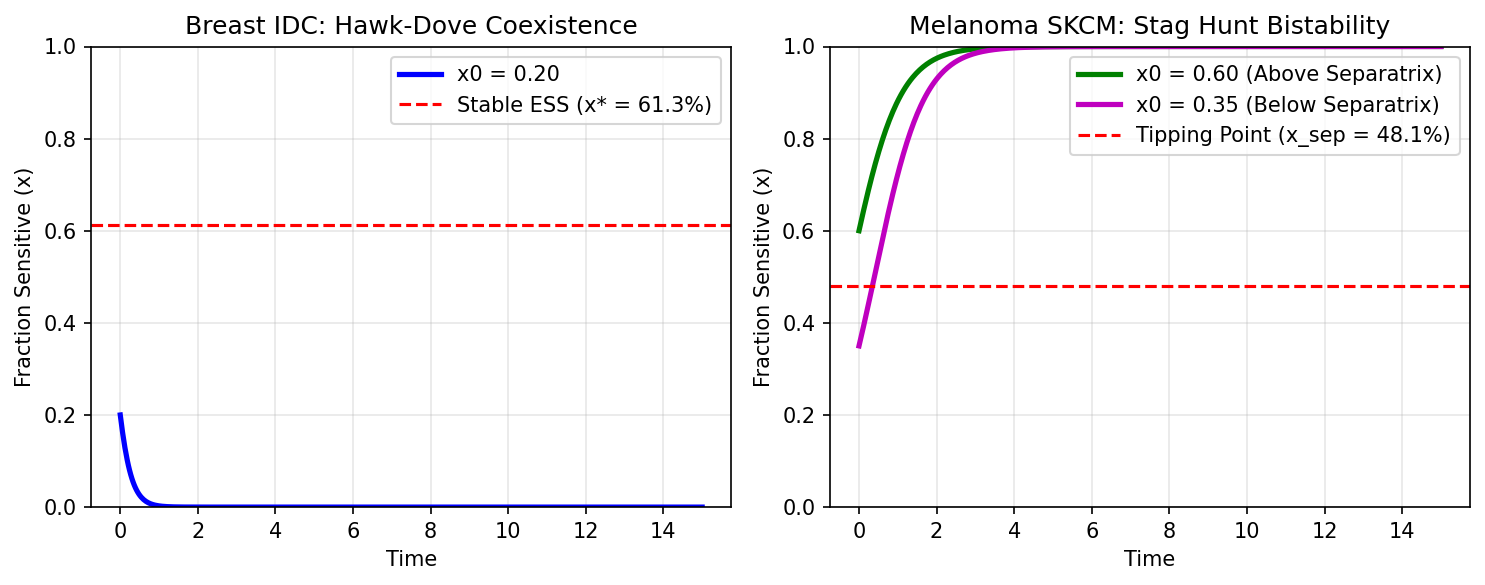

In [14]:
# Step 4: Interactive Visualization of Payoff Matrices and Adaptive Dosing
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

# Replicator dynamics ODE: dx/dt = x*(1-x)*(delta_S*x + delta_R*(1-x)) - u*(d_S - d_R)*x
def replicator(x, t, delta_S, delta_R, u, d_S, d_R):
    growth = x * (1.0 - x) * (delta_S * x + delta_R * (1.0 - x))
    kill = u * (d_S - d_R) * x
    return growth - kill

t = np.linspace(0, 15, 500)

# Breast IDC (Hawk-Dove: delta_S = -2.924, delta_R = -4.638, x* = 0.613)
x_hd = odeint(replicator, 0.20, t, args=(-2.924, -4.638, 0.0, 0.0, 0.0))

# Melanoma SKCM (Stag Hunt: delta_S = +1.633, delta_R = +1.515, x_sep = 0.481)
x_sh_above = odeint(replicator, 0.60, t, args=(1.633, 1.515, 0.0, 0.0, 0.0))
x_sh_below = odeint(replicator, 0.35, t, args=(1.633, 1.515, 0.0, 0.0, 0.0))

plt.figure(figsize=(10, 4), dpi=150)
plt.subplot(1, 2, 1)
plt.plot(t, x_hd, 'b-', lw=2.5, label='x0 = 0.20')
plt.axhline(0.613, color='r', linestyle='--', label='Stable ESS (x* = 61.3%)')
plt.title('Breast IDC: Hawk-Dove Coexistence')
plt.xlabel('Time')
plt.ylabel('Fraction Sensitive (x)')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(t, x_sh_above, 'g-', lw=2.5, label='x0 = 0.60 (Above Separatrix)')
plt.plot(t, x_sh_below, 'm-', lw=2.5, label='x0 = 0.35 (Below Separatrix)')
plt.axhline(0.481, color='r', linestyle='--', label='Tipping Point (x_sep = 48.1%)')
plt.title('Melanoma SKCM: Stag Hunt Bistability')
plt.xlabel('Time')
plt.ylabel('Fraction Sensitive (x)')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()